In [1]:
#202431070_AmirRafifAflah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#202431070_AmirRafifAflah
data = pd.read_csv("Mall_Customers.csv")
data

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [3]:
#202431070_AmirRafifAflah
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
#202431070_AmirRafifAflah
df = data.copy()
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [5]:
df = df.drop (['CustomerID', 'Gender', 'Age'], axis = 1)
df

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


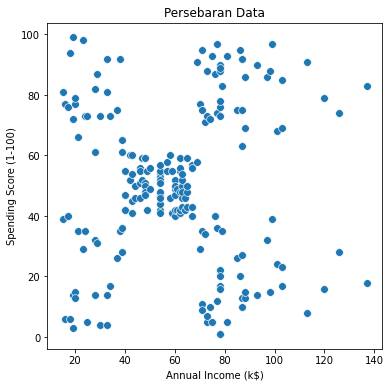

In [6]:
#202431070_AmirRafifAflah
plt.figure(figsize = (6,6))
sns.scatterplot(x = 'Annual Income (k$)',
                y = 'Spending Score (1-100)',
               data = df, s = 60)
plt.title('Persebaran Data')
plt.show()

In [7]:
#202431070_AmirRafifAflah
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    kmModel = KMeans(n_clusters = i, n_init=10)
    kmModel.fit(df)
    wcss.append(kmModel.inertia_)

C:\Users\raff_aflh\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:881: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


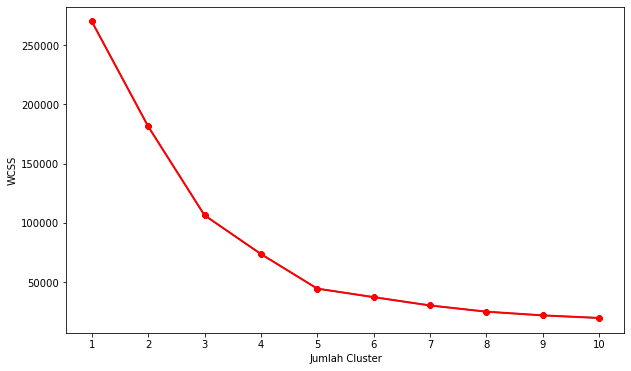

In [8]:
#202431070_AmirRafifAflah
plt.figure(figsize = (10,6))
plt.plot(range(1,11), wcss)
plt.plot(range(1,11), wcss, linewidth=2, color='red', marker='8')
plt.xlabel('Jumlah Cluster')
plt.xticks(np.arange(1,11,1))
plt.ylabel('WCSS')
plt.show()

In [9]:
#202431070_AmirRafifAflah
kmModelFix = KMeans(n_clusters=5, n_init=10, random_state=42)
kmModelFix.fit(df)

hasil_prediksi = kmModelFix.predict(df)
print(hasil_prediksi)

[2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 2 0 2 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 4 1 4 0 4 1 4 1 4 0 4 1 4 1 4 1 4 1 4 0 4 1 4 1 4
 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4 1
 4 1 4 1 4 1 4 1 4 1 4 1 4 1 4]


In [10]:
#202431070_AmirRafifAflah
df['label'] = hasil_prediksi
df.head()

,Annual Income (k$),Spending Score (1-100),label
0,15,39,2
1,15,81,3
2,16,6,2
3,16,77,3
4,17,40,2


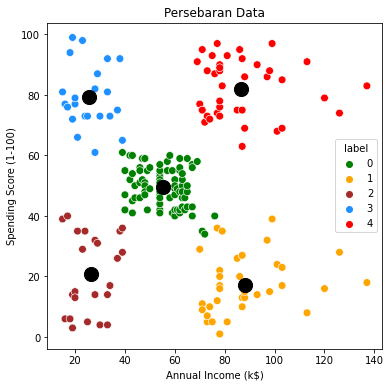

In [12]:
#202431070_AmirRafifAflah
plt.figure(figsize = (6,6))
sns.scatterplot(x = 'Annual Income (k$)',
                y = 'Spending Score (1-100)',
                hue = 'label',
                palette=['green', 'orange', 'brown', 'dodgerblue', 'red'],
                legend='full',data = df, s = 60)
plt.scatter(kmModelFix.cluster_centers_[:,0],
            kmModelFix.cluster_centers_[:,1],
           s=200, c='black', zorder= 5, label = 'Centroid')
plt.title('Persebaran Data')
plt.show()

In [13]:
#202431070_AmirRafifAflah
from sklearn.metrics import davies_bouldin_score

labels = kmModelFix.labels_
davies_bouldin_score(df,labels)

0.5715312291174508